# Aşama 16: Güney gökyüzü taraması

Kuzeyde yaptığımız enerjili, sezonlu taramayı güneyde (Dec −85° ile −5° arası) tekrarlıyoruz. Haritayı tamamlamak için.

**Beklenti:** Güneyde dedektör çok daha az hassas (Aşama 5: hassasiyet ~10 kat kötü). Atmosferik müonlardan kurtulmak için uygulanan sert enerji kesimi, düşük enerjili sinyali de yok ediyor. Anlamlı bir sıcak nokta çıkmaması büyük ihtimal; yine de tamamlanmış bir analiz için gerekli.

In [1]:
import sys; sys.path.append('../src')
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import icecube_ps as ps
importlib.reload(ps)
assert float(ps.SURUM) >= float('15.0'), f"src/icecube_ps.py eski sürüm ({getattr(ps, 'SURUM', 'yok')}). Yenisini kopyala, kernel'i yeniden başlat."
try:
    from tqdm.auto import tqdm          # ilerleme çubuğu
except ImportError:
    tqdm = None

pd.set_option('display.float_format', '{:.3g}'.format)
DATA, RESULTS = Path('../data'), Path('../results')
ev = ps.veri_yukle(DATA)
B = ps.ArkaPlan(ev['dec'].values)
print('icecube_ps', ps.SURUM, '| olay:', f'{len(ev):,}')
import os, time
from scipy import stats
N_CEKIRDEK = os.cpu_count()
sig0 = lambda p: max(0.0, ps.sigma(p))
alanlar, sureler, smearingler = ps.etkin_alanlari_yukle(DATA), ps.canli_sureler_yukle(DATA), ps.smearingleri_yukle(DATA)

c:\Users\musab\Desktop\Projects\Claude_Notrino_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


icecube_ps 15.0 | olay: 1,134,450


In [2]:
M = ps.SezonluModel(ev, alanlar, sureler, smearingler)
T = ps.SezonluTarayici(M)
DMIN, DMAX = -85.0, -5.0
ra_g, dec_g = ps.gok_izgarasi(0.7, DMIN, DMAX)
dosya = RESULTS / 'asama16_harita.npz'
if dosya.exists():
    h = np.load(dosya); ns_g, g_g, ts_g = h['ns'], h['gamma'], h['ts']
else:
    ns_g, g_g, ts_g = T.harita(ra_g, dec_g, ilerleme=tqdm)
    np.savez(dosya, ra=ra_g, dec=dec_g, ns=ns_g, gamma=g_g, ts=ts_g)
print(f'{len(ra_g):,} nokta, en büyük TS = {ts_g.max():.1f}')

100%|██████████| 115/115 [00:41<00:00,  2.80it/s]

38,397 nokta, en büyük TS = 25.0


⏱️ 50 karıştırılmış güney haritası (paralel). Kuzeydeki gibi her haritada da en sıcak noktaya ince tarama uygulanıyor.

In [3]:
HEDEF = 50
dosya_max = RESULTS / 'asama16_karisik_max_ts.npy'
dosya_ornek = RESULTS / 'asama16_karisik_ornek.npy'
max_ts = list(np.load(dosya_max)) if dosya_max.exists() else []
ornek = list(np.load(dosya_ornek)) if dosya_ornek.exists() else []
while len(max_ts) < HEDEF:
    n_yeni = min(2 * N_CEKIRDEK, HEDEF - len(max_ts))
    arg = [(0.7, 160_000 + len(max_ts) + i, DMIN, DMAX) for i in range(n_yeni)]
    for mx, ts_h in ps.paralel_sezonlu(arg, N_CEKIRDEK, DATA.resolve()):
        max_ts.append(mx)
        if len(ornek) < 3:
            ornek.append(ts_h)
    np.save(dosya_max, np.array(max_ts)); np.save(dosya_ornek, np.array(ornek))
    print(f'{len(max_ts)}/{HEDEF}', flush=True)
max_ts, ornek = np.array(max_ts), np.array(ornek)

24/50
48/50
50/50


In [4]:
havuz = ornek.ravel()
eta, sd = np.mean(havuz > 0), np.mean(havuz[havuz > 0])
yerel_p = lambda ts: eta * stats.chi2.sf(ts, df=sd) if ts > 0 else 1.0

en = int(np.argmax(ts_g))
ns_i, g_i, ts_i, ra_i, dec_i = ps.ince_tara(T, ra_g[en], dec_g[en], dec_min=DMIN, dec_max=DMAX)
k_asan = int(np.sum(max_ts >= ts_i))
p_post = (k_asan + 1) / (len(max_ts) + 1)
print(f'Güneyin en sıcak noktası: RA {ra_i:.2f}°, Dec {dec_i:.2f}°  nₛ = {ns_i:.1f}, γ = {g_i:.1f}, TS = {ts_i:.1f}')
print(f'Yerel: {sig0(yerel_p(ts_i)):.2f}σ   |   post-trial: {k_asan}/{len(max_ts)} karıştırılmış harita daha sıcak → {sig0(p_post):.2f}σ')
pd.DataFrame([dict(ra=ra_i, dec=dec_i, ns=ns_i, gamma=g_i, TS=ts_i, sigma_yerel=sig0(yerel_p(ts_i)),
                   k_asan=k_asan, n_karisik=len(max_ts), sigma_post=sig0(p_post))]).to_csv(
    RESULTS / 'asama16_guney.csv', index=False)

Güneyin en sıcak noktası: RA 344.77°, Dec -81.50°  nₛ = 17.5, γ = 4.2, TS = 26.2
Yerel: 5.03σ   |   post-trial: 27/50 karıştırılmış harita daha sıcak → 0.00σ


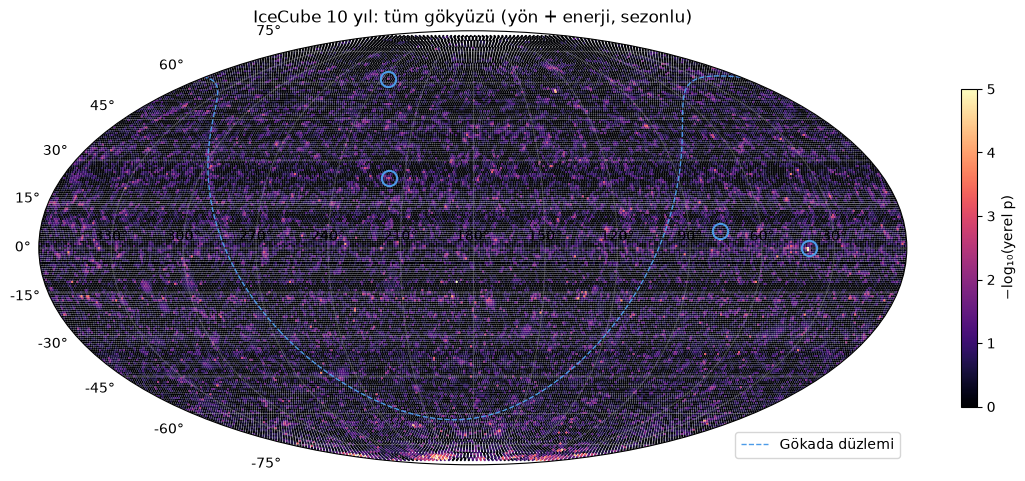

In [5]:
# Kuzey (Aşama 13) + güney tek haritada
kuzey = np.load(RESULTS / 'asama13_harita.npz')
h13 = pd.read_csv(RESULTS / 'asama13_sicak_nokta.csv').iloc[0]
eta_k, sd_k = h13['eta'], h13['sd']
gx = lambda r: -(np.radians(r) - np.pi)
fig = plt.figure(figsize=(14, 7.5))
ax = fig.add_subplot(111, projection='mollweide')
for ra, dec, ts, e_, s_ in [(kuzey['ra'], kuzey['dec'], kuzey['ts'], eta_k, sd_k), (ra_g, dec_g, ts_g, eta, sd)]:
    r = -np.log10(np.where(ts > 0, e_ * stats.chi2.sf(ts, df=s_), 1.0)); o = np.argsort(r)
    sc = ax.scatter(gx(ra[o]), np.radians(dec[o]), c=r[o], s=2.5, cmap='magma', vmin=0, vmax=5, lw=0)
fig.colorbar(sc, ax=ax, shrink=0.55, label='−log₁₀(yerel p)')
gr, gd = ps.galaksi_duzlemi(); gxx, gyy = gx(gr), np.radians(gd)
kop = np.where(np.abs(np.diff(gxx)) > np.pi)[0] + 1
ax.plot(np.insert(gxx, kop, np.nan), np.insert(gyy, kop, np.nan), color='#4c9be8', lw=1, ls='--', label='Gökada düzlemi')
for ad, (rk, dk) in ps.KAYNAKLAR.items():
    ax.plot(gx(rk), np.radians(dk), 'o', mfc='none', mec='#4c9be8', ms=11, mew=1.5)
ax.set_xticks(np.radians(np.arange(-150, 151, 30)))
ax.set_xticklabels([f'{(180 - t) % 360:.0f}°' for t in np.arange(-150, 151, 30)])
ax.grid(alpha=0.3); ax.legend(loc='lower right')
ax.set_title('IceCube 10 yıl: tüm gökyüzü (yön + enerji, sezonlu)')
plt.savefig(RESULTS / 'asama16_tum_gok.png', dpi=150, bbox_inches='tight')
plt.show()

## Yorumlarken

- Güneyde anlamlı bir sıcak nokta çıkmaması beklenen bir sonuç: dedektör orada çok daha az hassas. IceCube'un güney kaynak listesi de anlamlı bir fazlalık göstermedi.
- Bu aşama projeye yeni bir keşif katmıyor ama **tamamlanmış** bir analiz için gerekli: "Gökyüzünün yarısına bakmadık" eleştirisini kapatıyor. Bu notebook'un son grafiği, projenin vitrin görseli olabilir: tüm gökyüzü tek haritada.